# ЛР 09. Почему нейросеть предсказывает цену лучше или хуже?

**Данные:** `cars_processed.csv`. **Инструменты:** Keras 3 с PyTorch. **Время:** 90 минут.

За пару вы проведёте три эксперимента: измените активацию, измените лосс и найдёте момент, когда дальнейшее обучение перестаёт помогать. На каждой стадии сначала сформулируйте прогноз, затем проверьте его на данных. В конце выберите модель по validation и оцените её на test.

| Этап | Минуты |
|---|---:|
| Данные и линейная модель | 10 |
| График зависимости цены от года выпуска | 10 |
| Эксперимент с активацией | 20 |
| Эксперимент с лоссом | 15 |
| Недообучение, переобучение и ранняя остановка | 25 |
| Выбор модели, test и вывод | 10 |

## 1. Данные и линейная модель · 10 минут

Берём четыре знакомых признака: год, пробег, объём двигателя и пробег за год. Используем разбиение из ЛР 07: **train** — для обучения, **validation** — для выбора модели, **test** — для итоговой оценки. Масштаб признаков определяем по train. Для обучения цену делим на 10 000, для расчёта MAE возвращаем прогноз в евро.

Ячейка подготовки готова. Если пакетов нет, раскомментируйте установку, выполните её и перезапустите ядро.

In [1]:
# %pip install "keras>=3" torch numpy pandas scikit-learn matplotlib
import os
from pathlib import Path

os.environ['KERAS_BACKEND'] = 'torch'
import keras

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

print('Бэкенд:', keras.backend.backend())

path = Path('cars_processed.csv')
url = ('https://raw.githubusercontent.com/MVRonkin/BasicDataAnalysisCourse/'
       'refs/heads/main/Workshops/cars_processed.csv')
cars = pd.read_csv(path if path.exists() else url)
cars = cars.rename(columns={'Price(euro)': 'Price', 'Engine_capacity(cm3)': 'Engine'})

features = ['Year', 'Distance', 'Engine', 'km_year']
train, holdout = train_test_split(cars, test_size=0.4, random_state=42)
valid, test = train_test_split(holdout, test_size=0.5, random_state=43)

scaler = StandardScaler()
X_train = scaler.fit_transform(train[features])
X_valid = scaler.transform(valid[features])
X_test = scaler.transform(test[features])

price_unit = 10_000
y_train = train['Price'] / price_unit
print('Записей в train, validation и test:', len(train), len(valid), len(test))

Бэкенд: torch
Записей в train, validation и test: 19240 6413 6414


`Dense(1)` умножает четыре признака на веса, складывает результаты и прибавляет свободный член. Это линейная регрессия. `compile()` задаёт функцию потерь, `fit()` обучает модель, `predict()` возвращает прогноз.

Передайте в `fit()` данные validation. После каждой эпохи Keras посчитает на них лосс и MAE. Веса обновляются только по train.

В каждом запуске сохраняем веса эпохи с минимальной MAE на validation. Все 30 эпох выполняются: параметр `patience=30` здесь нужен, чтобы не прерывать сравнение раньше.

In [2]:
def keep_best(max_epochs):
    return keras.callbacks.EarlyStopping(
        monitor='val_mae', mode='min',
        patience=max_epochs, restore_best_weights=True
    )

keras.utils.set_random_seed(42)
linear = keras.Sequential([keras.Input(shape=(4,)), keras.layers.Dense(1)])
linear.compile(optimizer='adam', loss='mse', metrics=['mae'])

y_valid = valid['Price'] / price_unit
history_linear = linear.fit(
    X_train, y_train, validation_data=(X_valid, y_valid),
    epochs=30, batch_size=256, callbacks=[keep_best(30)], verbose=0
)

pred_linear = linear.predict(X_valid, verbose=0).ravel() * price_unit
print(f'MAE линейной модели на validation: {mean_absolute_error(valid["Price"], pred_linear):.0f} €')
print('Что Keras записал после каждой эпохи:', list(history_linear.history))

MAE линейной модели на validation: 4476 €
Что Keras записал после каждой эпохи: ['loss', 'mae', 'val_loss', 'val_mae']


**Проверьте себя.** Какие данные обновляют веса? Где вы заметите, что модель стала лучше предсказывать цену на записях, которых не было в обучении?

## 2. Смотрим на данные · 10 минут

Для самой представленной пары «марка — модель» покажем медианную цену по годам выпуска. Оставим годы с хотя бы 15 записями. Пунктир — прямая, проведённая по медианам.

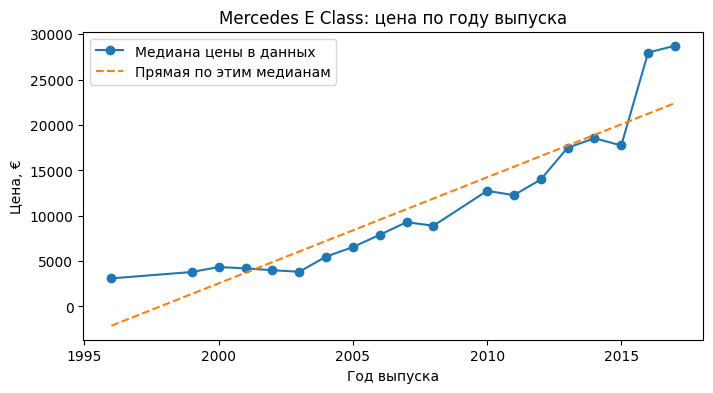

In [3]:
make, model_name = train.groupby(['Make', 'Model']).size().idxmax()
sample = train[(train['Make'] == make) & (train['Model'] == model_name)]
by_year = sample.groupby('Year')['Price'].agg(['size', 'median'])
by_year = by_year[by_year['size'] >= 15]

years = by_year.index.to_numpy()
straight = np.polyval(np.polyfit(years, by_year['median'], 1), years)

plt.figure(figsize=(8, 4))
plt.plot(years, by_year['median'], 'o-', label='Медиана цены в данных')
plt.plot(years, straight, '--', label='Прямая по этим медианам')
plt.title(f'{make} {model_name}: цена по году выпуска')
plt.xlabel('Год выпуска')
plt.ylabel('Цена, €')
plt.legend()
plt.show()

**Вопрос.** На каких участках прямая систематически выше или ниже точек? Это сравнение групп: у автомобилей разных годов могут различаться и другие признаки. График подсказывает гипотезу, а проверим её по MAE на validation.

## 3. Эксперимент: зачем нужна активация · 20 минут

Сравним **две сети с одинаковым числом слоёв и нейронов**. Меняем только активацию скрытых слоёв:

- `linear` оставляет результат слоя как есть. Даже несколько таких слоёв со смещениями дают линейную зависимость.
- `relu` оставляет положительные значения, а отрицательные заменяет нулём. При изменении входа часть нейронов начинает или перестаёт вносить вклад. Поэтому прогноз может менять наклон.

До запуска предположите, какая модель даст меньшую MAE. Ниже короткая функция для повторения опыта с другими настройками.

In [4]:
def make_model(widths=(16, 8), activation='relu', loss='mse', learning_rate=0.001):
    keras.utils.set_random_seed(42)
    layers = [keras.Input(shape=(4,))]
    for width in widths:
        layers.append(keras.layers.Dense(width, activation=activation))
    layers.append(keras.layers.Dense(1))
    model = keras.Sequential(layers)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate), loss=loss, metrics=['mae'])
    return model

In [5]:
linear_layers = make_model(activation='linear')
history_linear_layers = linear_layers.fit(
    X_train, y_train, validation_data=(X_valid, y_valid),
    epochs=30, batch_size=256, callbacks=[keep_best(30)], verbose=0
)

mlp_mse = make_model(activation='relu')
history_mse = mlp_mse.fit(
    X_train, y_train, validation_data=(X_valid, y_valid),
    epochs=30, batch_size=256, callbacks=[keep_best(30)], verbose=0
)

Меняем год выпуска, сохраняем один объём двигателя и один среднегодовой пробег. Общий пробег пересчитываем по возрасту. Для обеих моделей используем одинаковые входы. Промежуточные значения года нужны только для отрисовки линий.

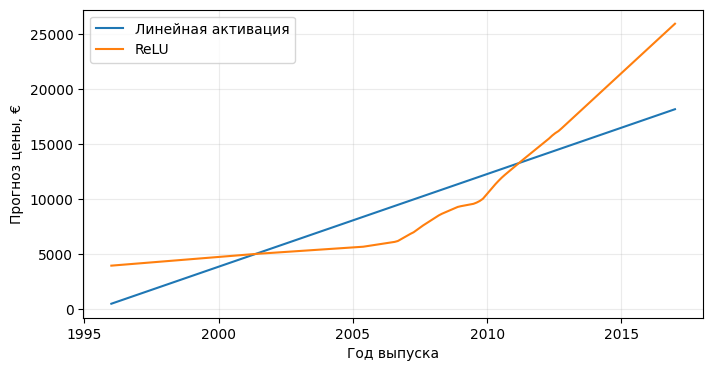

In [6]:
reference_year = int((train['Year'] + train['Age']).mode().iloc[0])
annual_km = sample['km_year'].median()
plot_years = np.linspace(years.min(), years.max(), 180)
grid = pd.DataFrame({
    'Year': plot_years,
    'Distance': (reference_year - plot_years) * annual_km,
    'Engine': sample['Engine'].median(),
    'km_year': annual_km,
})
X_grid = scaler.transform(grid[features])

plt.figure(figsize=(8, 4))
for name, model in [('Линейная активация', linear_layers), ('ReLU', mlp_mse)]:
    plt.plot(plot_years, model.predict(X_grid, verbose=0).ravel() * price_unit, label=name)
plt.xlabel('Год выпуска')
plt.ylabel('Прогноз цены, €')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [7]:
activation_rows = []
for name, history in [('Один Dense', history_linear), ('Слои linear', history_linear_layers),
                      ('Слои ReLU', history_mse)]:
    j = np.argmin(history.history['val_mae'])
    activation_rows.append([
        name, j + 1, history.history['mae'][j] * price_unit,
        history.history['val_mae'][j] * price_unit
    ])
display(pd.DataFrame(activation_rows, columns=[
    'Модель', 'Эпоха по validation', 'MAE train, €', 'MAE validation, €'
]).round(0))

,Модель,Эпоха по validation,"MAE train, €","MAE validation, €"
0,Один Dense,30,4491.0,4476.0
1,Слои linear,20,4324.0,4154.0
2,Слои ReLU,26,2925.0,2899.0


**Задание 1.** Сравните график и MAE. Стала ли сеть с линейной активацией гибче после добавления слоёв? Затем замените ReLU на `tanh` в отдельном запуске: переобучите сеть и сравните MAE на validation. Остальные настройки сохраните.

In [8]:
# Для задания замените activation и запустите эту ячейку.
activation = 'tanh'
trial = make_model(activation=activation)
trial_history = trial.fit(
    X_train, y_train, validation_data=(X_valid, y_valid),
    epochs=30, batch_size=256, callbacks=[keep_best(30)], verbose=0
)
j = np.argmin(trial_history.history['val_mae'])
print(f'{activation}: эпоха {j + 1}, MAE на validation = {trial_history.history["val_mae"][j] * price_unit:.0f} €')

tanh: эпоха 26, MAE на validation = 2910 €


## 4. Эксперимент: что меняет лосс · 15 минут

Сравним ту же ReLU-сеть при `loss='mse'` и `loss='mae'`. Для MSE ошибка в 3 000 € даёт в девять раз больший вклад, чем ошибка в 1 000 €. Для MAE — в три раза. Гипотеза: изменение лосса может по-разному сказаться на крупных ошибках и средней ошибке.

Лоссы в разных единицах напрямую не сравниваем. Обе модели оценим в евро по **MAE**, **RMSE** и **MAE для дорогих автомобилей**. Дорогими считаем автомобили с ценой выше 90-го процентиля train.

Для обоих лоссов выбираем эпоху по одному критерию: минимальной MAE на всём validation.

In [9]:
mlp_mae = make_model(activation='relu', loss='mae')
history_mae = mlp_mae.fit(
    X_train, y_train, validation_data=(X_valid, y_valid),
    epochs=30, batch_size=256, callbacks=[keep_best(30)], verbose=0
)

price_limit = train['Price'].quantile(0.9)
expensive = valid['Price'] > price_limit
loss_rows = []
for loss, model, history in [('MSE', mlp_mse, history_mse), ('MAE', mlp_mae, history_mae)]:
    epoch = np.argmin(history.history['val_mae']) + 1
    pred = model.predict(X_valid, verbose=0).ravel() * price_unit
    errors = valid['Price'].to_numpy() - pred
    loss_rows.append([loss, epoch, np.abs(errors).mean(), np.sqrt((errors ** 2).mean()),
                      np.abs(errors[expensive]).mean()])

print(f'Граница дорогой группы: {price_limit:.0f} €, записей в validation: {expensive.sum()}')
display(pd.DataFrame(loss_rows, columns=['Лосс', 'Эпоха по validation', 'MAE, €', 'RMSE, €', 'MAE дорогих, €']).round(0))

Граница дорогой группы: 19500 €, записей в validation: 645


,Лосс,Эпоха по validation,"MAE, €","RMSE, €","MAE дорогих, €"
0,MSE,26,2899.0,5962.0,9444.0
1,MAE,29,2769.0,6146.0,10222.0


**Задание 2.** Совпали ли победители по трём метрикам? Выберите лосс, если вам важно уменьшить средний промах по всему набору. Как изменится решение, если вас особенно интересуют дорогие машины?

## 5. Недообучение и переобучение · 25 минут

По одному значению ошибки трудно понять, что случилось. Нужны обе кривые:

- Если простая модель ошибается даже на train и после обучения заметно уступает более гибкой, это признак **недообучения**. Сверьтесь с результатом линейных слоёв и ReLU.
- Если ошибка на train продолжает уменьшаться, а на validation после некоторого момента растёт, это **переобучение**.

Чтобы увидеть второй эффект за одну пару, специально возьмём только **128 записей из train** и более широкую сеть. Проверочная выборка остаётся прежней. На графике сравниваем эпохи одной и той же модели на одних и тех же данных.

In [10]:
small_train = train.sample(n=128, random_state=42)
X_small = scaler.transform(small_train[features])
y_small = small_train['Price'] / price_unit

wide = make_model(widths=(128, 64), learning_rate=0.003)
history_wide = wide.fit(
    X_small, y_small, validation_data=(X_valid, y_valid),
    epochs=250, batch_size=32, validation_batch_size=2048, callbacks=[keep_best(250)], verbose=0
)

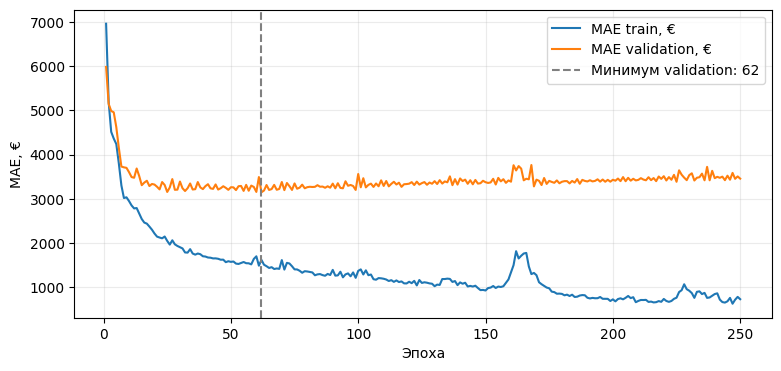

,"MAE train, €","MAE validation, €"
Эпоха,,
1,6959.0,5982.0
62,1620.0,3149.0
250,733.0,3458.0


In [11]:
curves = pd.DataFrame({
    'MAE train, €': np.array(history_wide.history['mae']) * price_unit,
    'MAE validation, €': np.array(history_wide.history['val_mae']) * price_unit
}, index=pd.Index(range(1, 251), name='Эпоха'))
best_epoch = curves['MAE validation, €'].idxmin()

ax = curves.plot(figsize=(9, 4))
ax.axvline(best_epoch, color='gray', linestyle='--', label=f'Минимум validation: {best_epoch}')
ax.set_ylabel('MAE, €')
ax.legend()
ax.grid(alpha=0.25)
plt.show()

display(curves.loc[sorted({1, best_epoch, 250})].round(0))

**Задание 3.** На какой эпохе MAE на validation минимальна? Что произошло с обеими ошибками к последней эпохе? Почему выбор эпохи по train дал бы другое решение?

График показывает весь запуск, включая последнюю эпоху. После завершения в `wide` восстановлены веса лучшей эпохи по MAE на validation.

### Останавливаем обучение по validation

Заново обучаем такую же сеть на тех же 128 записях. `EarlyStopping` прекращает обучение, если MAE на validation не улучшается 60 эпох подряд, и возвращает веса лучшей из пройденных эпох. Сравните с результатом на 250-й эпохе.

In [12]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_mae', mode='min', patience=60, restore_best_weights=True
)
wide_stopped = make_model(widths=(128, 64), learning_rate=0.003)
history_stopped = wide_stopped.fit(
    X_small, y_small, validation_data=(X_valid, y_valid),
    epochs=250, batch_size=32, validation_batch_size=2048,
    callbacks=[early_stop], verbose=0
)

pred = wide_stopped.predict(X_valid, verbose=0).ravel() * price_unit
print('Восстановлена эпоха:', np.argmin(history_stopped.history['val_mae']) + 1)
print('Пройдено эпох:', len(history_stopped.history['loss']))
print(f'MAE на validation после восстановления весов: {mean_absolute_error(valid["Price"], pred):.0f} €')

Восстановлена эпоха: 62
Пройдено эпох: 122
MAE на validation после восстановления весов: 3149 €


**Дополнительный опыт.** Уменьшите `patience` до 20. Сравните число пройденных эпох, восстановленную эпоху и MAE. Почему слишком маленький `patience` может остановить обучение до более удачной эпохи?

## 6. Выбираем модель и проверяем на test · 10 минут

Сначала для каждой конфигурации восстанавливаем веса её лучшей эпохи по MAE на validation. Затем по той же метрике выбираем конфигурацию сети. Только после этого сравниваем выбранную сеть с линейной моделью на всём test.

Границы трёх ценовых групп берём из train. Вклад группы в общее снижение MAE равен её доле в test, умноженной на снижение MAE внутри группы.

In [13]:
candidates = [
    ('ReLU + MSE', mlp_mse, history_mse),
    ('ReLU + MAE', mlp_mae, history_mae),
    (f'{activation} + MSE', trial, trial_history)
]
validation_rows = []
for name, model, history in candidates:
    epoch = np.argmin(history.history['val_mae']) + 1
    pred = model.predict(X_valid, verbose=0).ravel() * price_unit
    validation_rows.append([name, epoch, mean_absolute_error(valid['Price'], pred)])

selection = pd.DataFrame(validation_rows, columns=['Сеть', 'Эпоха', 'MAE validation, €'])
display(selection.round(2))
chosen_idx = selection['MAE validation, €'].idxmin()
chosen_name, chosen, _ = candidates[chosen_idx]
print('Выбранная сеть:', chosen_name, '— эпоха', selection.loc[chosen_idx, 'Эпоха'])

result = test[['Make', 'Model', 'Year', 'Price']].copy()
result['Прогноз линейной модели'] = linear.predict(X_test, verbose=0).ravel() * price_unit
result['Прогноз сети'] = chosen.predict(X_test, verbose=0).ravel() * price_unit
errors = result[['Прогноз линейной модели', 'Прогноз сети']].sub(result['Price'], axis=0).abs()
display(errors.mean().rename('MAE на test, €').round(0))

Выбранная сеть: ReLU + MAE — эпоха 29


,Сеть,Эпоха,"MAE validation, €"
0,ReLU + MSE,26,2898.56
1,ReLU + MAE,29,2769.20
2,tanh + MSE,26,2909.92


Прогноз линейной модели    4533.0
Прогноз сети               2773.0
Name: MAE на test, €, dtype: float64

In [14]:
low, high = train['Price'].quantile([1 / 3, 2 / 3])
groups = pd.cut(result['Price'], bins=[-np.inf, low, high, np.inf],
                labels=['Низкая цена', 'Средняя цена', 'Высокая цена'])
summary = errors.groupby(groups, observed=True).mean()
summary.columns = ['MAE линейной, €', 'MAE сети, €']
summary.insert(0, 'Записей', groups.value_counts())
summary['Снижение MAE, €'] = summary['MAE линейной, €'] - summary['MAE сети, €']
summary['Вклад в снижение общей MAE, €'] = (
    summary['Записей'] / len(test) * summary['Снижение MAE, €']
)
print(f'Границы групп по train: {low:.0f} и {high:.0f} €')
display(summary.round(2))

Границы групп по train: 4600 и 9700 €


,Записей,"MAE линейной, €","MAE сети, €","Снижение MAE, €","Вклад в снижение общей MAE, €"
Price,,,,,
Низкая цена,2195,4137.00,1184.57,2952.43,1010.38
Средняя цена,2167,3428.53,1944.46,1484.07,501.40
Высокая цена,2052,6123.33,5347.73,775.60,248.13


**Вопрос.** Какая ценовая группа дала наибольший вклад в снижение общей MAE? Объясните этот вклад двумя числами: долей записей группы и снижением MAE внутри неё.

## Бонус. Фактические цены и прогнозы регрессоров

Берём реальные записи из test для той же пары «марка — модель», которую выбрали по train. Линейная модель, MLP, ближайшие соседи, дерево и случайный лес предсказывают цену **для одних и тех же автомобилей**. Для каждого года показываем медиану фактических цен и медианы прогнозов; оставляем годы с хотя бы пятью записями.

Чёрная линия — фактическая цена из данных (ground truth). Остальные линии — прогнозы. Это сравнение по годам для одной модели автомобиля, а итоговая MAE выше рассчитана по всему test.

Линия линейной модели здесь тоже может менять наклон: в записях разных годов отличаются и пробег, и объём двигателя. В опыте с активацией выше мы строили отдельный сценарий с контролируемыми входами.

Mercedes E Class: 190 записей на графике


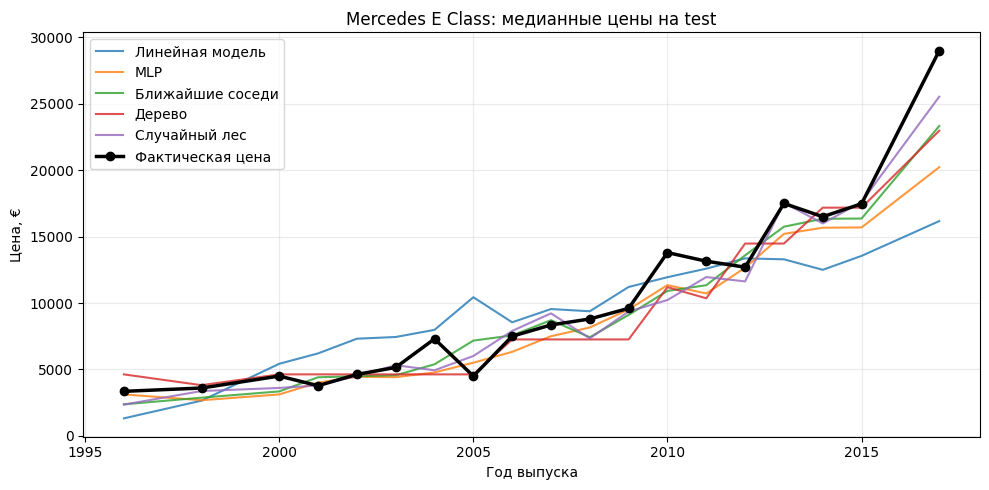

In [15]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

models = {
    'Ближайшие соседи': KNeighborsRegressor(n_neighbors=20),
    'Дерево': DecisionTreeRegressor(max_depth=5, random_state=42),
    'Случайный лес': RandomForestRegressor(n_estimators=60, random_state=42, n_jobs=2),
}

mask = test['Make'].eq(make) & test['Model'].eq(model_name)
X_bonus = X_test[mask.to_numpy()]
bonus = result.loc[mask, ['Year', 'Price', 'Прогноз линейной модели', 'Прогноз сети']].copy()
bonus = bonus.rename(columns={'Price': 'Фактическая цена', 'Прогноз линейной модели': 'Линейная модель',
                              'Прогноз сети': 'MLP'})
for name, regressor in models.items():
    regressor.fit(X_train, y_train)
    bonus[name] = regressor.predict(X_bonus) * price_unit

by_year = bonus.groupby('Year')
counts = by_year.size()
curves_bonus = by_year.median().loc[counts >= 5]
print(f'{make} {model_name}: {int(counts[counts >= 5].sum())} записей на графике')
ax = curves_bonus.drop(columns='Фактическая цена').plot(figsize=(10, 5), alpha=0.8)
ax.plot(curves_bonus.index, curves_bonus['Фактическая цена'],
        color='black', marker='o', linewidth=2.5, label='Фактическая цена')
ax.set(title=f'{make} {model_name}: медианные цены на test', xlabel='Год выпуска', ylabel='Цена, €')
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Бонус. Классификация: два полумесяца

У точки два признака: координаты `x₁` и `x₂`. Цель — предсказать, к какому из двух полумесяцев она относится. В `make_moons` задаём `noise=0.25`: координаты искажаются, поэтому часть точек разных классов оказывается рядом.

Сравним, **какой формы границу строят разные модели**. Все обучаются на одних и тех же 600 точках. На 200 точках validation выбираем эпоху сети. Ещё 200 точек оставляем для итогового сравнения.

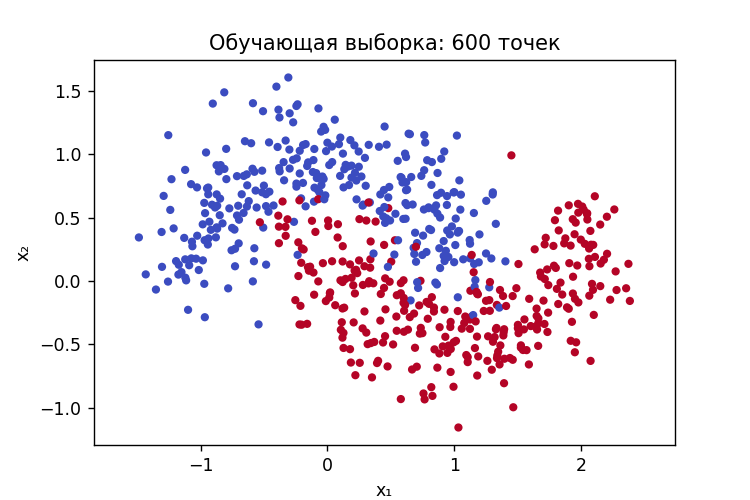

In [16]:
from sklearn.datasets import make_moons
from sklearn.metrics import accuracy_score

X_moons, y_moons = make_moons(n_samples=1000, noise=0.25, random_state=100)

X_m_train, X_m_holdout, y_m_train, y_m_holdout = train_test_split(
    X_moons, y_moons, test_size=0.4, random_state=42, stratify=y_moons
)
X_m_valid, X_m_test, y_m_valid, y_m_test = train_test_split(
    X_m_holdout, y_m_holdout, test_size=0.5, random_state=43, stratify=y_m_holdout
)

plt.figure(figsize=(6, 4))
plt.scatter(*X_m_train.T, c=y_m_train, cmap='coolwarm', s=14)
plt.title('Обучающая выборка: 600 точек')
plt.xlabel('x₁')
plt.ylabel('x₂')
plt.axis('equal')
plt.show()

### 1. Что меняет активация в скрытых слоях

У обеих сетей архитектура **2 → 16 → 8 → 1**. Меняем только активацию скрытых слоёв: `linear` или `relu`. На выходе обеих сетей стоит `sigmoid`: результат от 0 до 1, при значении от 0,5 предсказываем класс 1. Для обучения задаём `binary_crossentropy`.

У сети с `linear` всё выражение до сигмоиды сводится к `a*x₁ + b*x₂ + c`. Сигмоида равна 0,5 при входе 0, поэтому граница — прямая `a*x₁ + b*x₂ + c = 0`. ReLU позволяет менять наклон этой границы в разных частях плоскости.

In [17]:
def make_moon_net(activation):
    keras.utils.set_random_seed(42)
    model = keras.Sequential([
        keras.Input(shape=(2,)),
        keras.layers.Dense(16, activation=activation),
        keras.layers.Dense(8, activation=activation),
        keras.layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=keras.optimizers.Adam(0.01), loss='binary_crossentropy')
    return model

moon_nets = {}
for activation in ['linear', 'relu']:
    net = make_moon_net(activation)
    early_stop = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=20, restore_best_weights=True
    )
    history = net.fit(
        X_m_train, y_m_train, validation_data=(X_m_valid, y_m_valid),
        epochs=120, batch_size=64, callbacks=[early_stop], verbose=0
    )
    moon_nets[activation] = net
    print(f'{activation}: лучшая эпоха по val_loss — {np.argmin(history.history["val_loss"]) + 1}')

linear: лучшая эпоха по val_loss — 20
relu: лучшая эпоха по val_loss — 30


### 2. Сравниваем границы на одних и тех же точках

Добавим логистическую регрессию, k ближайших соседей, дерево и случайный лес. **Цвет точки — истинный класс, цвет фона — прогноз, крестик — ошибка.** В заголовке — доля верных ответов на test.

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

moon_models = {
    'Логистическая регрессия': LogisticRegression(),
    'kNN, k=15': KNeighborsClassifier(n_neighbors=15),
    'Дерево, глубина 5': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Случайный лес': RandomForestClassifier(n_estimators=60, random_state=42),
}
for model in moon_models.values():
    model.fit(X_m_train, y_m_train)

def predict_moon_net(net, X):
    return (net.predict(X, verbose=0).ravel() >= 0.5).astype(int)

In [19]:
from matplotlib.colors import ListedColormap

x1 = np.linspace(X_m_train[:, 0].min() - 0.25, X_m_train[:, 0].max() + 0.25, 180)
x2 = np.linspace(X_m_train[:, 1].min() - 0.25, X_m_train[:, 1].max() + 0.25, 180)
xx, yy = np.meshgrid(x1, x2)
moon_grid = np.column_stack([xx.ravel(), yy.ravel()])
moon_colors = ['#2375b7', '#c05b26']
moon_cmap = ListedColormap(moon_colors)

def plot_moon_boundary(ax, grid_pred, X, y, pred, title):
    region = grid_pred.reshape(xx.shape)
    ax.contourf(xx, yy, region, levels=[-0.5, 0.5, 1.5],
                colors=moon_colors, alpha=0.18)
    ax.contour(xx, yy, region, levels=[0.5], colors='#444444', linewidths=0.9)
    ax.scatter(*X.T, c=y, cmap=moon_cmap, vmin=0, vmax=1, s=17, zorder=2)
    wrong = pred != y
    ax.scatter(*X[wrong].T, marker='x', color='black', s=31, zorder=3)
    ax.set_aspect('equal')
    ax.set_title(title)

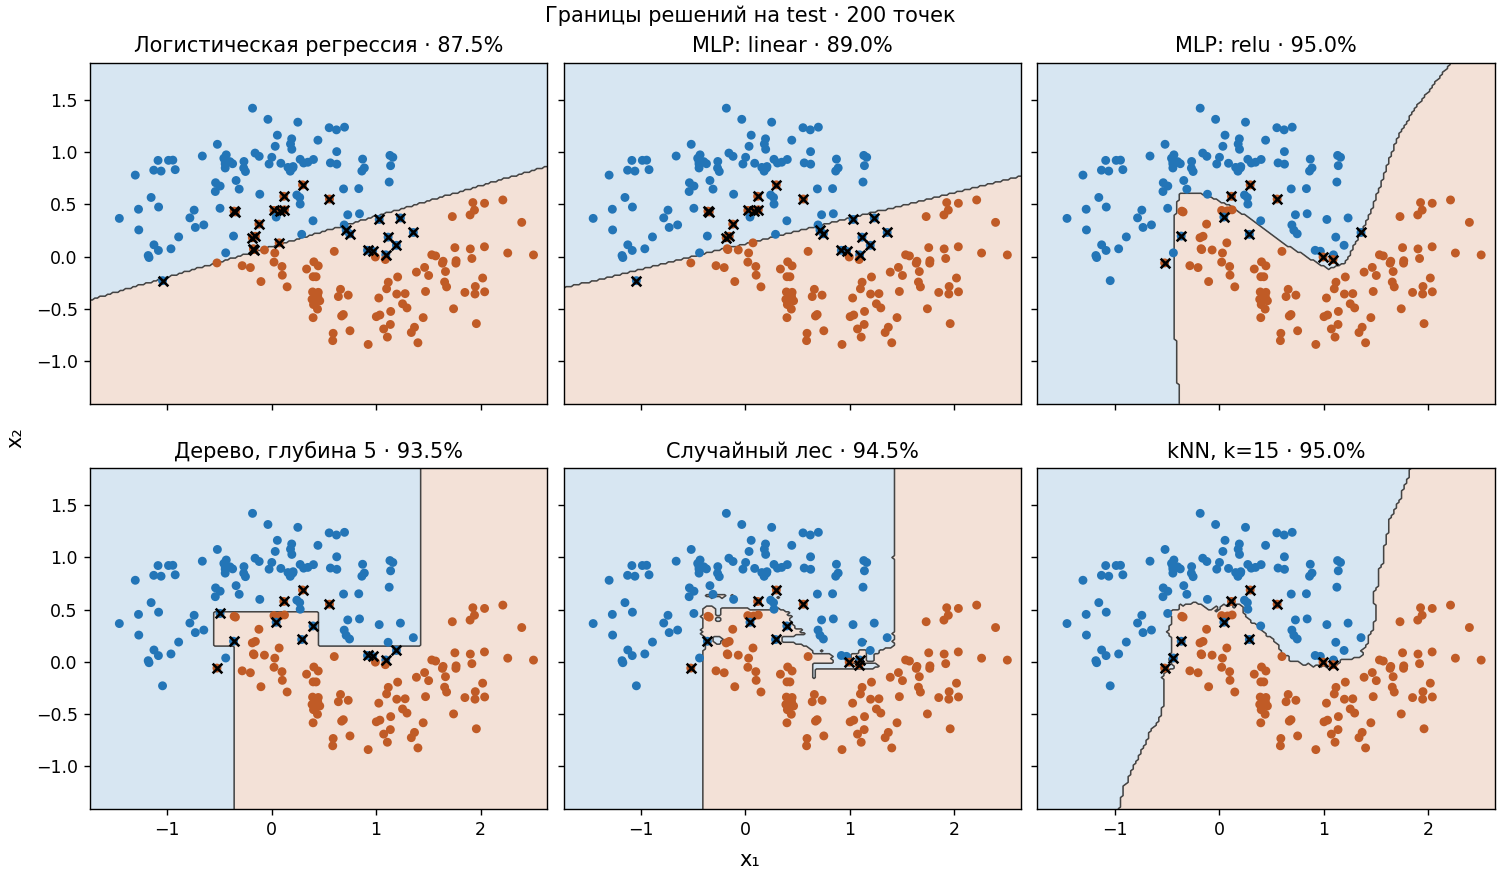

In [20]:
moon_predictions = {
    name: (model.predict(moon_grid), model.predict(X_m_test))
    for name, model in moon_models.items()
}
for activation, net in moon_nets.items():
    moon_predictions[f'MLP: {activation}'] = (
        predict_moon_net(net, moon_grid), predict_moon_net(net, X_m_test)
    )

# Линейные модели рядом, нелинейные — в остальных панелях.
order = ['Логистическая регрессия', 'MLP: linear', 'MLP: relu',
         'Дерево, глубина 5', 'Случайный лес', 'kNN, k=15']
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True,
                         layout='constrained')
fig.suptitle('Границы решений на test · 200 точек')
for ax, name in zip(axes.flat, order):
    grid_pred, pred = moon_predictions[name]
    accuracy = accuracy_score(y_m_test, pred)
    plot_moon_boundary(ax, grid_pred, X_m_test, y_m_test, pred, f'{name} · {accuracy:.1%}')
    ax.label_outer()
fig.supxlabel('x₁')
fig.supylabel('x₂')
plt.show()

Сравните верхний ряд: **почему у MLP с линейной активацией граница осталась прямой**, хотя у неё столько же нейронов, сколько у MLP с ReLU? Сравните дерево и лес: дерево делит плоскость порогами по одной координате за раз, поэтому отдельные участки границы идут вдоль осей. У леса итог получается голосованием деревьев.

### 3. Один параметр: сколько соседей брать?

У kNN с `k=1` класс определяет одна ближайшая точка, с `k=15` или `k=301` — большинство соседей. Обучаем все три варианта на тех же 600 точках и сравниваем **train и validation**. Здесь измеряем долю ошибок: чем меньше, тем лучше.

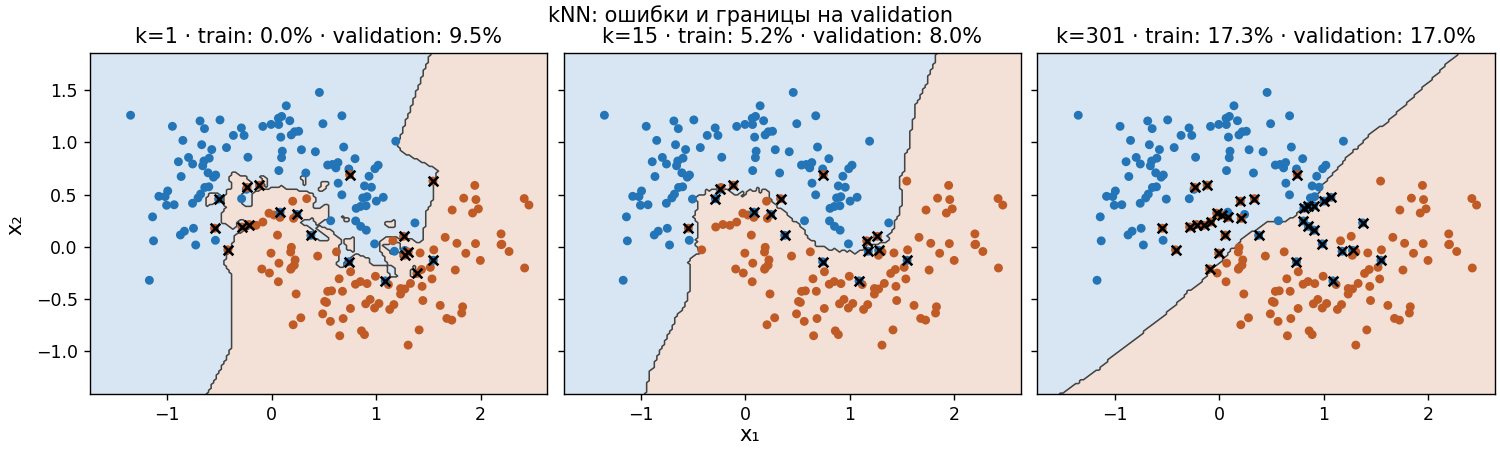

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True, sharey=True,
                         layout='constrained')
fig.suptitle('kNN: ошибки и границы на validation')
for ax, k in zip(axes, [1, 15, 301]):
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_m_train, y_m_train)
    pred_train = knn.predict(X_m_train)
    pred_valid = knn.predict(X_m_valid)
    err_train = (pred_train != y_m_train).mean()
    err_valid = (pred_valid != y_m_valid).mean()
    plot_moon_boundary(ax, knn.predict(moon_grid), X_m_valid, y_m_valid, pred_valid,
                       f'k={k} · train: {err_train:.1%} · validation: {err_valid:.1%}')
fig.supxlabel('x₁')
fig.supylabel('x₂')
plt.show()

**Почему при `k=1` ошибка на train равна нулю?** При проверке на train каждая точка сама себе ближайший сосед. Найдите на графике маленькие области вокруг отдельных точек и объясните, почему они могут давать ошибки на новых данных.

**Почему большое `k` может ухудшить результат?** Посмотрите, что происходит у загнутых концов полумесяцев: при большом `k` в голосование попадают и далёкие точки. Поменяйте список значений `k` в ячейке и проверьте, при каком значении ошибка на validation меньше.